# **TP N°2 : Classification avec des Réseaux de Neurones Entièrement Connectés (FCNN)**

**Elaboré par :** Ayeb Farah

## **Importation des bibliothéques**

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_circles, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout # Added Input here
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical
from sklearn.datasets import make_blobs
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)


In [4]:
# Fixer la graine aléatoire pour la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

## **Partie I : Classification binaire**


### **1. Création et exploration du dataset binaire**

**a. Création des données**

In [5]:
X, y = make_circles(n_samples=1000, noise=0.03, random_state=42)

**b. Afficher les dimensions du dataset. Quelles sont les dimensions de l’entrée et de la
sortie du classifieur?**

In [6]:
print(f"Dimensions de X (entrées): {X.shape}")
print(f"Dimensions de y (sorties): {y.shape}")
print(f"Nombre de features en entrée: {X.shape[1]}")
print(f"Nombre de classes en sortie: {len(np.unique(y))}")

Dimensions de X (entrées): (1000, 2)
Dimensions de y (sorties): (1000,)
Nombre de features en entrée: 2
Nombre de classes en sortie: 2


**c. Visualiser les données.**

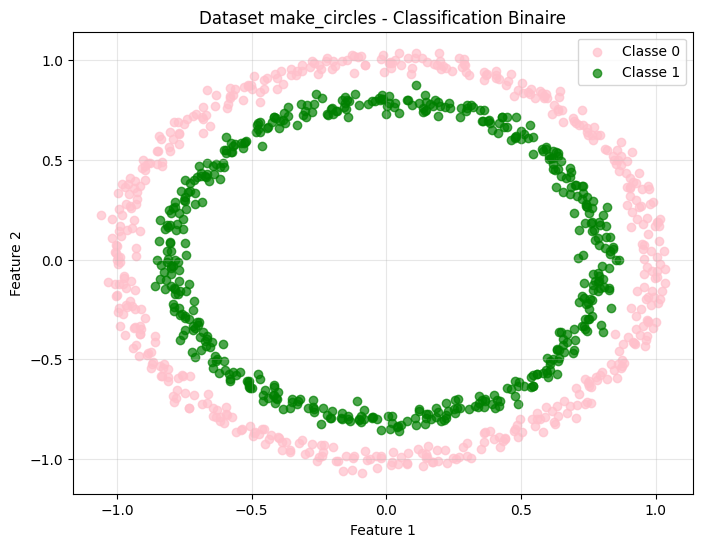

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(X[y==0, 0], X[y==0, 1], c='pink', label='Classe 0', alpha=0.7)
plt.scatter(X[y==1, 0], X[y==1, 1], c='green', label='Classe 1', alpha=0.7)
plt.title('Dataset make_circles - Classification Binaire')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**d. Ce dataset nécessite une fonction linéaire ou non linéaire pour séparer ses classes ?
Justifier.**


Ce dataset nécessite une fonction non linéaire pour séparer ses classes.

**Justification:** Les données sont organisées en deux cercles concentriques ce qui rend impossible une séparation linéaire par une droite.

**e. Diviser les données en ensembles d’apprentissage et de test à l’aide de train test split().
Fixer la valeur test size a 0.2, c’est à dire 80% données d’entrainement, et 20% données
de test et comme la répartition se produit de manière aléatoire entre les données, fixer
la valeur de random state a 42 afin que la répartition soit reproductible.**

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\n--- Division des données ---")
print(f"Ensemble d'apprentissage: {X_train.shape[0]} échantillons")
print(f"Ensemble de test: {X_test.shape[0]} échantillons")


--- Division des données ---
Ensemble d'apprentissage: 800 échantillons
Ensemble de test: 200 échantillons


### **2. Définition du modèle**

### **2.1 Cycle de vie d’un modèle :**

Un modèle a un cycle de vie. Les cinq étapes du cycle de vie sont les suivantes :
1. Définir le modèle
2. Compiler le modèle
3. Entrainer le modèle
4. Évaluer le modèle
5. Faire des prédictions

### **2.2 Définition du modèle FCNN :**

**a. Créer un nouveau modèle model = Sequential()**

In [9]:
model_binaire = Sequential()
model_binaire.add(Input(shape=(2,))) # Added Input layer
model_binaire.add(Dense(100, activation='sigmoid', name='couche_cachee'))
model_binaire.add(Dense(1, activation='sigmoid', name='couche_sortie'))

**b. Afficher un résumé concis de l'architecture du modèle, y compris le nombre de
paramètres et la forme de la sortie de chaque couche.**

In [10]:
print("\n--- Résumé de l'architecture du modèle ---")
model_binaire.summary()


--- Résumé de l'architecture du modèle ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ couche_cachee (Dense)           │ (None, 100)            │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ couche_sortie (Dense)           │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401 (1.57 KB)

 Trainable params: 401 (1.57 KB)

 Non-trainable params: 0 (0.00 B)

### **2.3 Compilation du modèle :**

In [11]:
model_binaire.compile(
    loss='binary_crossentropy',
    optimizer=SGD(learning_rate=0.5),
    metrics=['accuracy']
)

### **2.4 Entrainement du modèle :**

In [12]:
history_binaire = model_binaire.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=0
)

In [41]:
print("\nProgression de l'entraînement (toutes les 10 époques):")
print("-" * 70)
print(f"{'Epoque':<10} {'Loss Train':<15} {'Acc Train':<15} {'Loss Test':<15} {'Acc Test':<15}")
print("-" * 70)

for epoch in range(0, 101, 10):
    if epoch == 0:
        print(f"{epoch:<10} {'N/A':<15} {'N/A':<15} {'N/A':<15} {'N/A':<15}")
    else:
        idx = epoch - 1
        print(f"{epoch:<10} {history_binaire.history['loss'][idx]:<15.4f} "
              f"{history_binaire.history['accuracy'][idx]:<15.4f} "
              f"{history_binaire.history['val_loss'][idx]:<15.4f} "
              f"{history_binaire.history['val_accuracy'][idx]:<15.4f}")



Progression de l'entraînement (toutes les 10 époques):
----------------------------------------------------------------------
Epoque     Loss Train      Acc Train       Loss Test       Acc Test       
----------------------------------------------------------------------
0          N/A             N/A             N/A             N/A            
10         0.8789          0.4775          0.7605          0.5000         
20         0.7699          0.4875          0.7105          0.5000         
30         0.7433          0.4950          0.7096          0.5000         
40         0.7310          0.4925          0.7092          0.5000         
50         0.7239          0.4938          0.7085          0.5000         
60         0.7193          0.5013          0.7077          0.5000         
70         0.7159          0.5000          0.7068          0.5000         
80         0.7134          0.4988          0.7059          0.5000         
90         0.7113          0.4900          0.7051   

### **2.5 Evaluation du modèle**

In [42]:
print("\n--- Évaluation finale du modèle ---")
test_loss, test_acc = model_binaire.evaluate(X_test, y_test, verbose=0)
print(f"Précision finale sur l'ensemble de test: {test_acc:.4f}")


--- Évaluation finale du modèle ---
Précision finale sur l'ensemble de test: 0.5000


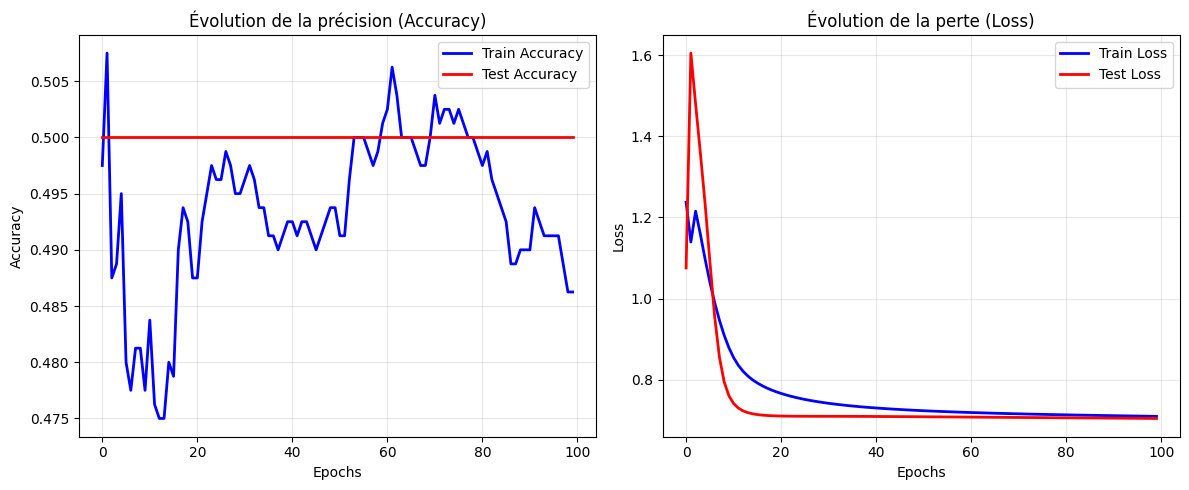


RÉSULTATS FINAUX
Accuracy finale sur le train : 0.4863
Accuracy finale sur le test  : 0.5000
Loss finale sur le train      : 0.7095
Loss finale sur le test       : 0.7043


In [43]:
plt.figure(figsize=(12, 5))

# Sous-plot 1 : Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_binaire.history['accuracy'], 'b-', label='Train Accuracy', linewidth=2)
plt.plot(history_binaire.history['val_accuracy'], 'r-', label='Test Accuracy', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Évolution de la précision (Accuracy)')
plt.legend()
plt.grid(True, alpha=0.3)

# Sous-plot 2 : Loss
plt.subplot(1, 2, 2)
plt.plot(history_binaire.history['loss'], 'b-', label='Train Loss', linewidth=2)
plt.plot(history_binaire.history['val_loss'], 'r-', label='Test Loss', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Évolution de la perte (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Affichage des valeurs finales
print("\n" + "="*50)
print("RÉSULTATS FINAUX")
print("="*50)
print(f"Accuracy finale sur le train : {history_binaire.history['accuracy'][-1]:.4f}")
print(f"Accuracy finale sur le test  : {history_binaire.history['val_accuracy'][-1]:.4f}")
print(f"Loss finale sur le train      : {history_binaire.history['loss'][-1]:.4f}")
print(f"Loss finale sur le test       : {history_binaire.history['val_loss'][-1]:.4f}")

**1. Tracer la (les) frontière(s) de décision pour les ensembles d’entrainement et de test.**

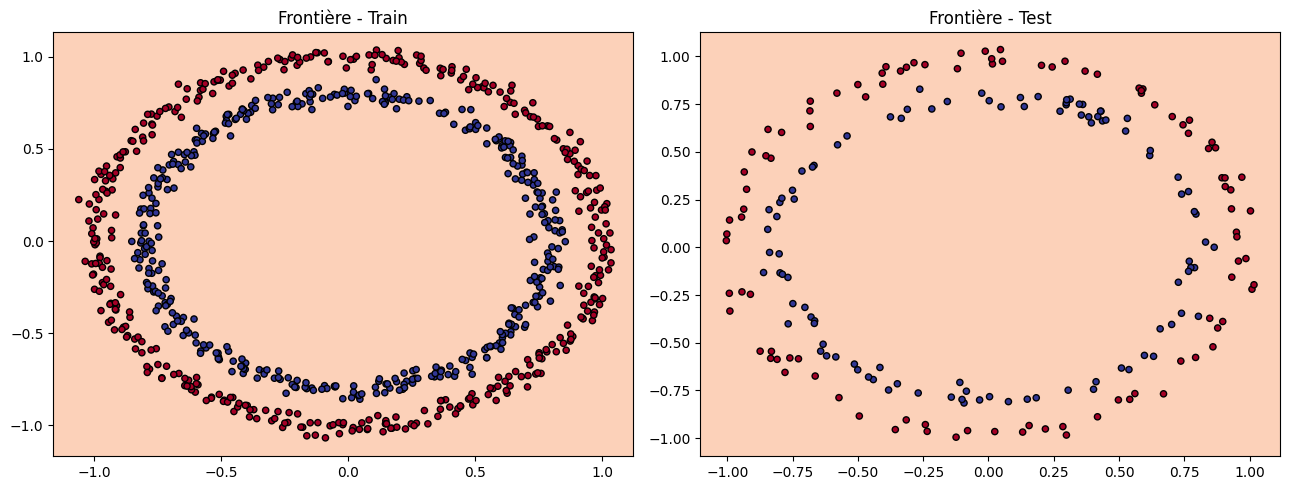

In [13]:
def plot_decision_boundary(model, X, y, title="Frontière de décision"):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0)
    Z = (Z > 0.5).astype(int).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='k', s=20)
    plt.title(title)

# 1. Tracer les frontières de décision
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plt.sca(axes[0])
plot_decision_boundary(model_binaire, X_train, y_train, "Frontière - Train")
plt.sca(axes[1])
plot_decision_boundary(model_binaire, X_test,  y_test,  "Frontière - Test")
plt.tight_layout()
plt.show()


La figure des frontières de décision montre :

1. **Absence de séparation nette** entre les deux classes
   - Les zones bleues et rouges sont entremêlées aléatoirement
   - Aucune frontière circulaire n'a été apprise

2. **Comportement identique** sur train et test
   - Frontière aléatoire sur l'ensemble d'entraînement
   - Frontière aléatoire sur l'ensemble de test

3. **Corrélation avec les métriques**
   - Accuracy à 50% = prédiction aléatoire
   - Loss à 0.693 = aucune certitude dans les prédictions

**2. Quel est le problème de ce modèle ?**




 Le modèle avec activation sigmoïde dans la couche cachée souffre du problème de **vanishing gradient**.
Les gradients deviennent extrêmement petits lors de la rétropropagation, empêchant la mise à jour
effective des poids. Visuellement, cela se traduit par :

- Une frontière de décision aléatoire (mélange des couleurs)
- Une incapacité à apprendre la forme circulaire des données
- Des performances équivalentes à un classifieur aléatoire (50%)

La figure montre clairement qu'aucune structure n'a été apprise, confirmant l'analyse numérique
(loss constante à 0.693, accuracy à 50%).


**3. Comment améliorer les performances du modèle ? Proposer 3 techniques
d’amélioration et implémenter une (ou la combinaison) des solutions proposées.**


 Pour améliorer les performances du modèle, on peut:

* Normaliser les données en utilisant StandardScaler pour centrer et réduire les features.
* Changer l'optimiseur → Adam (adaptatif, converge plus vite que SGD)
* Ajouter des couches cachées.supplémentaires (réseau plus profond)
* Augmenter le nombre d'époques ou le taux d'apprentissage.



=== MODÈLE AMÉLIORÉ (Adam + réseau plus profond) ===
Train → Loss: 0.0005 | Accuracy: 1.0000
Test  → Loss: 0.0041  | Accuracy: 1.0000


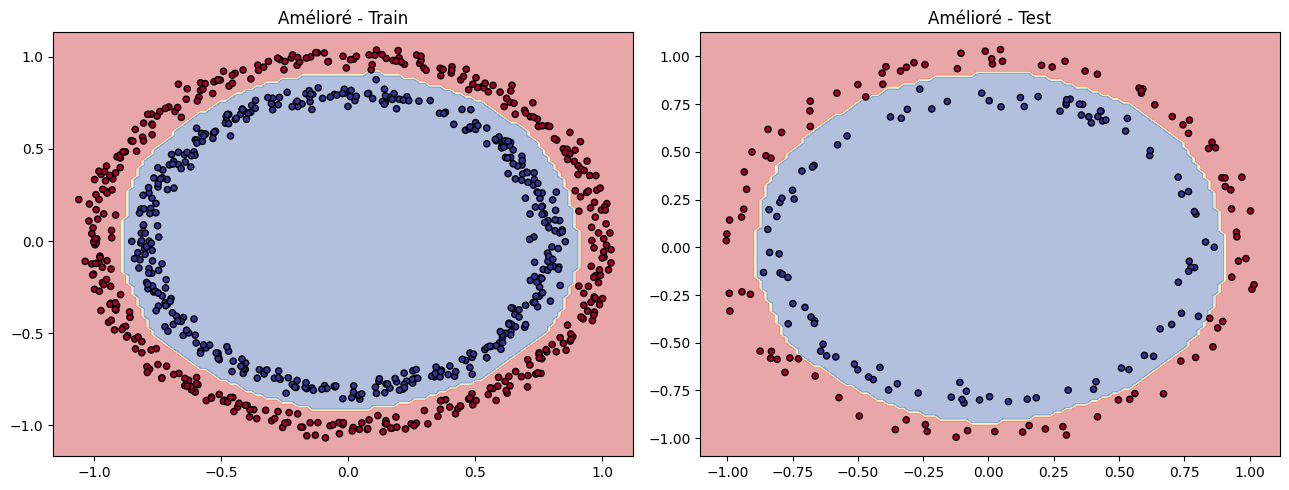

In [14]:
print("\n=== MODÈLE AMÉLIORÉ (Adam + réseau plus profond) ===")

model_improved = Sequential([
    Dense(64,  activation='relu', input_shape=(2,)),
    Dense(64,  activation='relu'),
    Dense(32,  activation='relu'),
    Dense(1,   activation='sigmoid')
])

model_improved.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history_improved = model_improved.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_test, y_test),
    verbose=0
)

# Évaluation finale
loss_train, acc_train = model_improved.evaluate(X_train, y_train, verbose=0)
loss_test,  acc_test  = model_improved.evaluate(X_test,  y_test,  verbose=0)
print(f"Train → Loss: {loss_train:.4f} | Accuracy: {acc_train:.4f}")
print(f"Test  → Loss: {loss_test:.4f}  | Accuracy: {acc_test:.4f}")

# Frontière de décision du modèle amélioré
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plt.sca(axes[0])
plot_decision_boundary(model_improved, X_train, y_train, "Amélioré - Train")
plt.sca(axes[1])
plot_decision_boundary(model_improved, X_test,  y_test,  "Amélioré - Test")
plt.tight_layout()
plt.show()

## **Partie II :  La multi-Classification :**

**1. Créer des données multi-classes avec make-blobs().**

In [16]:
X2, y2 = make_blobs(
    n_samples=1000,
    n_features=2,     # 2 dimensions (x1, x2)
    centers=4,        # 4 classes
    cluster_std=1.5,  # dispersion des clusters
    random_state=42
)


**2. Diviser les données en ensembles d’apprentissage et de test**

In [17]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)
print(f"\nTaille train : {X2_train.shape[0]} | Taille test : {X2_test.shape[0]}")


Taille train : 800 | Taille test : 200


**3. Visualiser les données**

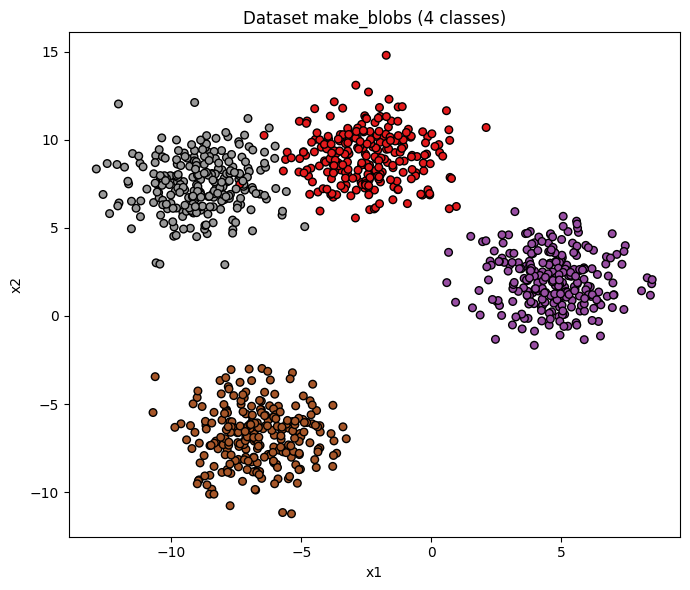

In [18]:
plt.figure(figsize=(7, 6))
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='Set1', edgecolors='k', s=30)
plt.title("Dataset make_blobs (4 classes)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()
plt.show()

**4. Ce dataset nécessite une fonction linéaire ou non linéaire pour séparer ses classes ?
Justifier.**

Les blobs sont séparables linéairement (clusters distincts / gaussiens).
Une fonction linéaire peut suffire car chaque blob est séparable des autres par une droite un classifieur linéaire comme la régression logistique serait théoriquement suffisant pour ce problème, mais un réseau non linéaire donnera de meilleures marges de séparation.

**5. Proposer une architecture basée sur FCNN pour la classification de ces données et la
développer.**



In [28]:
# Normalisation des données (pour améliorer la convergence)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X2_train)
X_test_scaled = scaler.transform(X2_test)

# One-hot encoding des labels (car classification multi-classes)
y_train_cat = to_categorical(y2_train, num_classes=4)
y_test_cat = to_categorical(y2_test, num_classes=4)

# Construction du modèle
model_multi = Sequential([
    Input(shape=(2,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')  # 4 neurones pour 4 classes
])

In [30]:
# Compilation du modèle
model_multi.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Résumé du modèle
print("\nRésumé du modèle :")
model_multi.summary()


Résumé du modèle :


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404 (9.39 KB)

 Trainable params: 2,404 (9.39 KB)

 Non-trainable params: 0 (0.00 B)

**6. Entrainer le modèle et afficher les mesures de progression toutes les 10 époques, y
compris la perte, la précision, la perte de test et la précision de test.**

In [31]:
history_multi = model_multi.fit(
    X_train_scaled, y_train_cat,
    epochs=100,
    batch_size=32,
    validation_data=(X_test_scaled, y_test_cat),
    verbose=0,
    callbacks=[
        tf.keras.callbacks.LambdaCallback(
            on_epoch_end=lambda epoch, logs: (
                print(f"{epoch+1:3d}/100   trainset_loss:  {logs['loss']:.4f}        "
                      f" trainset_accuracy: {logs['accuracy']:.4f}    validationset_loss:    {logs['val_loss']:.4f}        "
                      f" validationset_accuracy: {logs['val_accuracy']:.4f}")
                if (epoch + 1) % 10 == 0 else None
            )
        )
    ]
)


 10/100   trainset_loss:  0.0396         trainset_accuracy: 0.9950    validationset_loss:    0.0289         validationset_accuracy: 1.0000
 20/100   trainset_loss:  0.0214         trainset_accuracy: 0.9937    validationset_loss:    0.0098         validationset_accuracy: 1.0000
 30/100   trainset_loss:  0.0190         trainset_accuracy: 0.9937    validationset_loss:    0.0066         validationset_accuracy: 1.0000
 40/100   trainset_loss:  0.0182         trainset_accuracy: 0.9937    validationset_loss:    0.0054         validationset_accuracy: 1.0000
 50/100   trainset_loss:  0.0177         trainset_accuracy: 0.9937    validationset_loss:    0.0048         validationset_accuracy: 1.0000
 60/100   trainset_loss:  0.0173         trainset_accuracy: 0.9937    validationset_loss:    0.0045         validationset_accuracy: 1.0000
 70/100   trainset_loss:  0.0170         trainset_accuracy: 0.9937    validationset_loss:    0.0042         validationset_accuracy: 1.0000
 80/100   trainset_loss:  0

**7. Afficher toutes les métriques de classification vues en cours (précision, rappel, score
F1, matrice de confusion, ...) et expliquer l’utilité de chacune d’elles en interprétant les
résultats obtenus.**


Classification Report :
              precision    recall  f1-score   support

    Classe 0       1.00      1.00      1.00        49
    Classe 1       1.00      1.00      1.00        41
    Classe 2       1.00      1.00      1.00        53
    Classe 3       1.00      1.00      1.00        57

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


 EXPLICATION DES MÉTRIQUES :
--------------------------------------------------
1. PRÉCISION (Precision) :
   Formule : TP / (TP + FP)
   Utilité : Mesure la proportion de prédictions correctes parmi
             toutes les prédictions faites pour une classe donnée.
   Interprétation : Une précision élevée signifie que lorsque le
                   modèle prédit une classe, il a rarement tort.

2. RAPPEL (Recall) :
   Formule : TP / (TP + FN)
   Utilité : Mesure la proportion d'éléments d'une classe qui ont
             été correctem

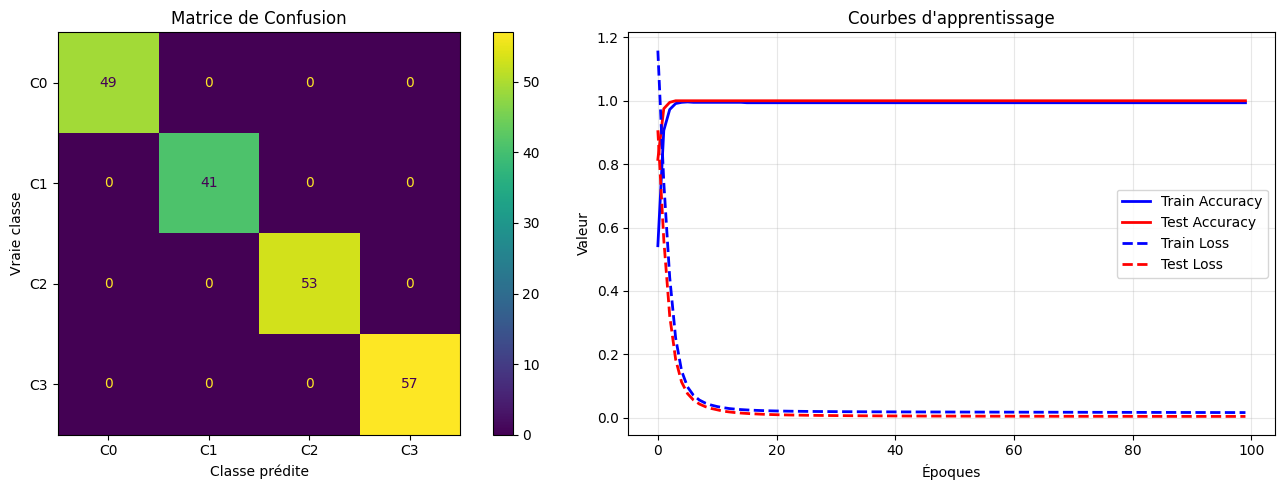

In [32]:
# Prédictions sur l'ensemble de test
y_pred_proba = model_multi.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

# Classification report
print("\nClassification Report :")
print("="*50)
print(classification_report(y2_test, y_pred, target_names=[f'Classe {i}' for i in range(4)]))
print("="*50)

# Explication des métriques
print("\n EXPLICATION DES MÉTRIQUES :")
print("-" * 50)
print("1. PRÉCISION (Precision) :")
print("   Formule : TP / (TP + FP)")
print("   Utilité : Mesure la proportion de prédictions correctes parmi")
print("             toutes les prédictions faites pour une classe donnée.")
print("   Interprétation : Une précision élevée signifie que lorsque le")
print("                   modèle prédit une classe, il a rarement tort.")
print()
print("2. RAPPEL (Recall) :")
print("   Formule : TP / (TP + FN)")
print("   Utilité : Mesure la proportion d'éléments d'une classe qui ont")
print("             été correctement identifiés.")
print("   Interprétation : Un rappel élevé signifie que le modèle manque")
print("                   peu d'éléments de cette classe.")
print()
print("3. F1-SCORE :")
print("   Formule : 2 × (Précision × Rappel) / (Précision + Rappel)")
print("   Utilité : Moyenne harmonique entre précision et rappel.")
print("   Interprétation : Utile quand on veut un équilibre entre les deux.")
print()
print("4. SUPPORT :")
print("   Utilité : Nombre réel d'occurrences de chaque classe dans le test.")
print()

# Matrice de confusion
print("\nMatrice de confusion :")
print("-" * 50)
cm = confusion_matrix(y2_test, y_pred)
print(cm)
print("\nLecture de la matrice :")
print("- Lignes = vraies classes")
print("- Colonnes = classes prédites")
print("- Les valeurs sur la diagonale = bonnes classifications")

# Visualisation de la matrice de confusion
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matrice de confusion
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f'C{i}' for i in range(4)]).plot(ax=axes[0])
axes[0].set_title('Matrice de Confusion')
axes[0].set_xlabel('Classe prédite')
axes[0].set_ylabel('Vraie classe')

# Courbes d'apprentissage
axes[1].plot(history_multi.history['accuracy'], 'b-', label='Train Accuracy', linewidth=2)
axes[1].plot(history_multi.history['val_accuracy'], 'r-', label='Test Accuracy', linewidth=2)
axes[1].plot(history_multi.history['loss'], 'b--', label='Train Loss', linewidth=2)
axes[1].plot(history_multi.history['val_loss'], 'r--', label='Test Loss', linewidth=2)
axes[1].set_xlabel('Époques')
axes[1].set_ylabel('Valeur')
axes[1].set_title('Courbes d\'apprentissage')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**8. Tracer la (les) frontières(s) de décision pour les ensembles d’entrainement et de test.**

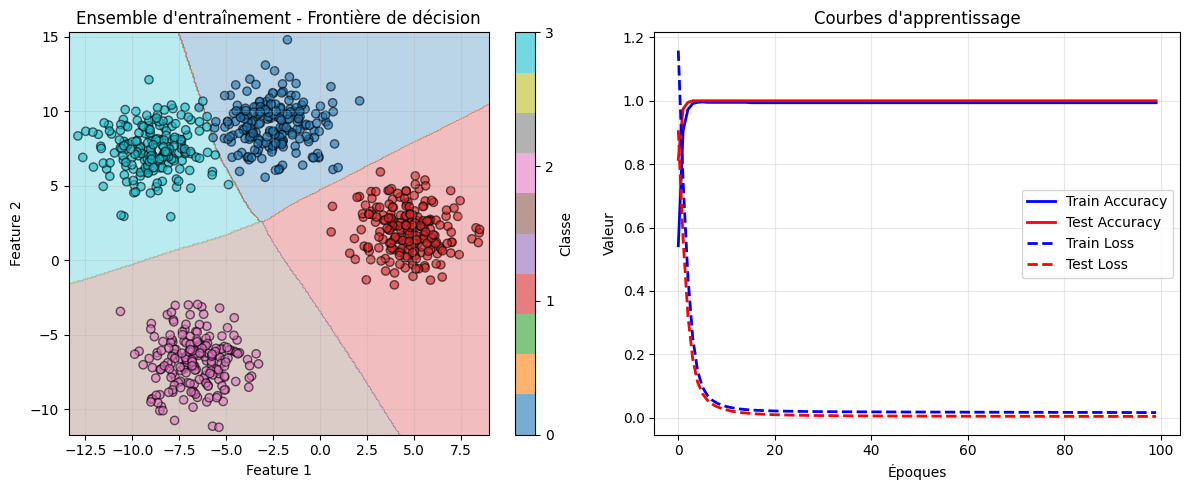

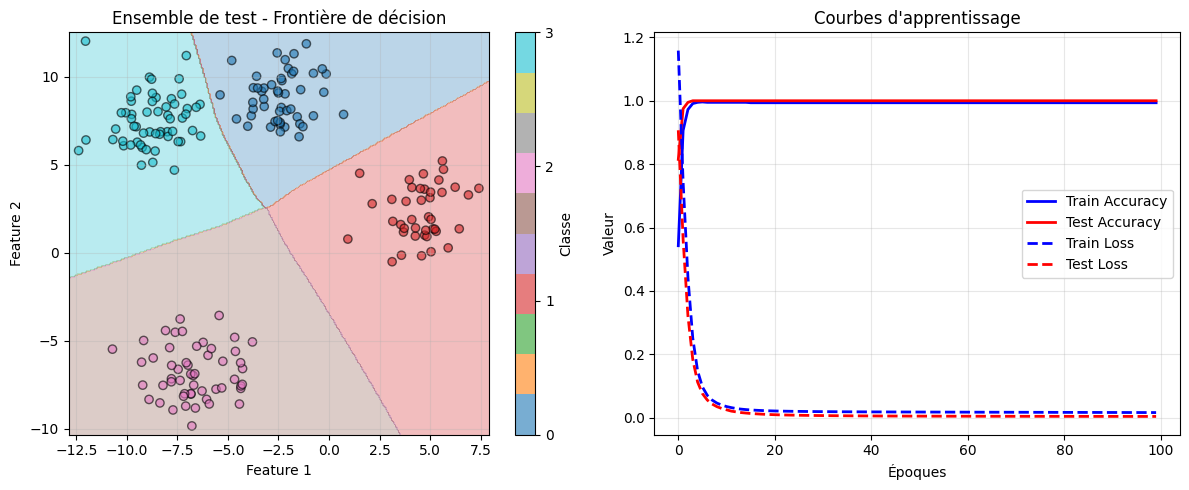

In [36]:
def plot_multiclass_decision_boundary(model, X, y, X_scaled, scaler, title):
    # Définir la grille
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    # Normaliser la grille et prédire
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid)
    Z = model.predict(grid_scaled, verbose=0)
    Z = np.argmax(Z, axis=1).reshape(xx.shape)

    # Tracer
    plt.figure(figsize=(12, 5))

    # Frontière de décision
    plt.subplot(1, 2, 1)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='tab10', alpha=0.6, edgecolors='k')
    plt.title(f'{title} - Frontière de décision')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.colorbar(scatter, ticks=[0, 1, 2, 3], label='Classe')
    plt.grid(True, alpha=0.3)

    # Courbes d'apprentissage
    plt.subplot(1, 2, 2)
    plt.plot(history_multi.history['accuracy'], 'b-', label='Train Accuracy', linewidth=2)
    plt.plot(history_multi.history['val_accuracy'], 'r-', label='Test Accuracy', linewidth=2)
    plt.plot(history_multi.history['loss'], 'b--', label='Train Loss', linewidth=2)
    plt.plot(history_multi.history['val_loss'], 'r--', label='Test Loss', linewidth=2)
    plt.xlabel('Époques')
    plt.ylabel('Valeur')
    plt.title('Courbes d\'apprentissage')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Tracer pour l'ensemble d'entraînement et de test
plot_multiclass_decision_boundary(model_multi, X2_train, y2_train, X_train_scaled, scaler, "Ensemble d'entraînement")
plot_multiclass_decision_boundary(model_multi, X2_test, y2_test, X_test_scaled, scaler, "Ensemble de test")

**9. Etudier l’impact de l’augmentation du nombre d’échantillons dans le dataset sur
l’exactitude de classification, et afficher la courbe de la progression de l’exactitude de
classification en fonction du nombre d’échantillons dans le dataset.**


Test en cours...
--------------------------------------------------------------------------------
Taille     Acc Train    Acc Test     Différence  
--------------------------------------------------------------------------------
100        1.0000       1.0000       0.0000      
200        1.0000       1.0000       0.0000      
500        1.0000       1.0000       0.0000      
1000       0.9987       1.0000       -0.0013     
1500       0.9975       1.0000       -0.0025     
2000       0.9975       1.0000       -0.0025     
3000       0.9996       0.9967       0.0029      
5000       0.9995       0.9970       0.0025      
--------------------------------------------------------------------------------


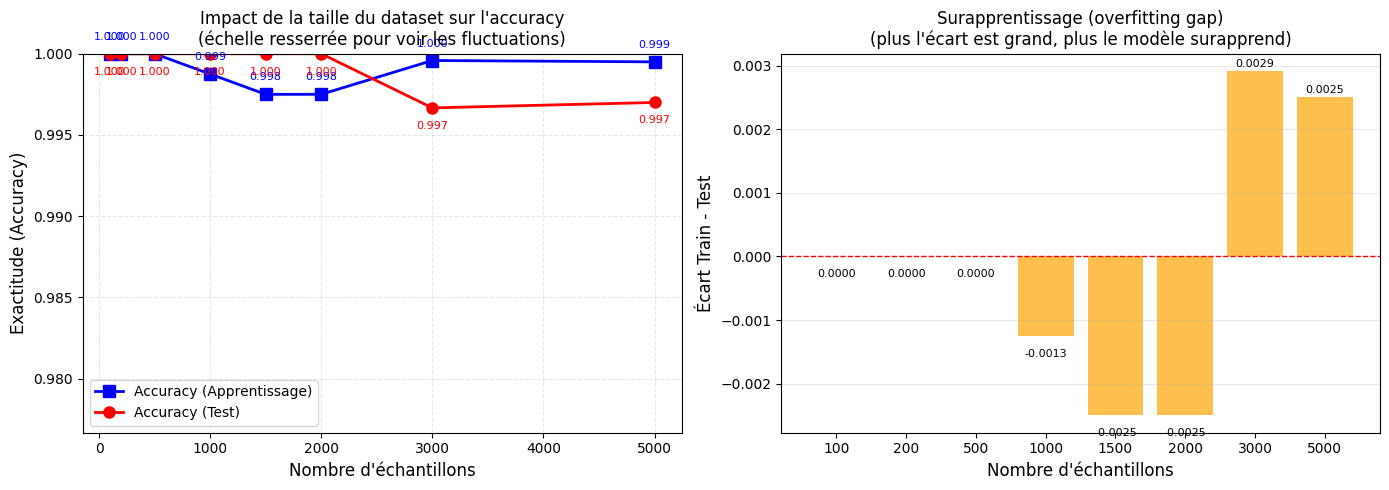


--- Version zoomée pour mieux visualiser les fluctuations ---


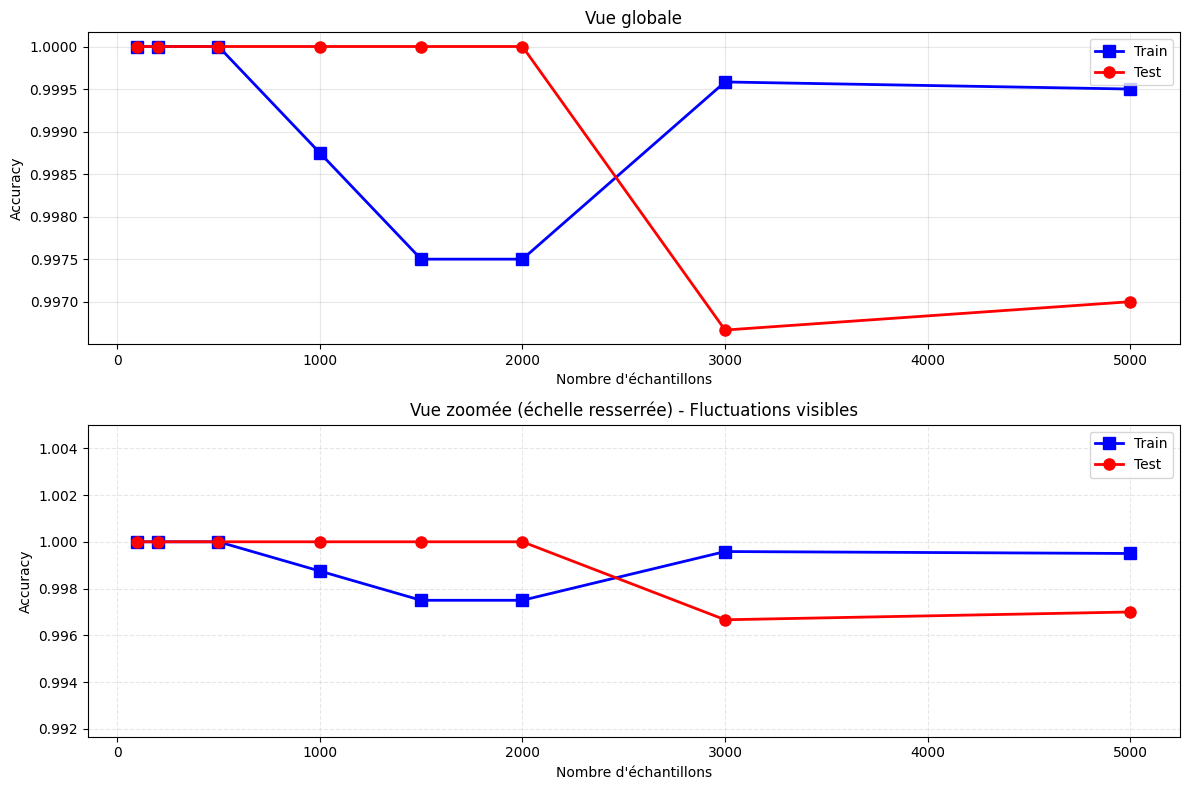


STATISTIQUES DES PERFORMANCES

Accuracy Train :
  - Minimum : 0.9975
  - Maximum : 1.0000
  - Moyenne : 0.9991
  - Écart-type : 0.001004

Accuracy Test :
  - Minimum : 0.9967
  - Maximum : 1.0000
  - Moyenne : 0.9992
  - Écart-type : 0.001374


In [39]:
# Différentes tailles de dataset à tester
sample_sizes = [100, 200, 500, 1000, 1500, 2000, 3000, 5000]
accuracies_train = []
accuracies_test = []

print("\nTest en cours...")
print("-" * 80)
print(f"{'Taille':<10} {'Acc Train':<12} {'Acc Test':<12} {'Différence':<12}")
print("-" * 80)

for n_samples in sample_sizes:
    # Création du dataset avec plus de bruit pour voir l'effet
    X_temp, y_temp = make_blobs(
        n_samples=n_samples,
        n_features=2,
        centers=4,
        cluster_std=1.2,  # Augmenté de 0.8 à 1.2 pour plus de difficulté
        random_state=42
    )

    # Division
    X_train_temp, X_test_temp, y_train_temp, y_test_temp = train_test_split(
        X_temp, y_temp, test_size=0.2, random_state=42
    )

    # Normalisation
    scaler_temp = StandardScaler()
    X_train_temp_scaled = scaler_temp.fit_transform(X_train_temp)
    X_test_temp_scaled = scaler_temp.transform(X_test_temp)

    # One-hot encoding
    y_train_temp_cat = to_categorical(y_train_temp, num_classes=4)
    y_test_temp_cat = to_categorical(y_test_temp, num_classes=4)

    # Création du modèle avec régularisation pour éviter le surapprentissage
    model_temp = Sequential([
        Input(shape=(2,)),
        Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.2),
        Dense(4, activation='softmax')
    ])

    model_temp.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    # Entraînement avec early stopping
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    model_temp.fit(
        X_train_temp_scaled, y_train_temp_cat,
        epochs=100,
        batch_size=32,
        validation_data=(X_test_temp_scaled, y_test_temp_cat),
        verbose=0,
        callbacks=[early_stop]
    )

    # Évaluation
    _, train_acc = model_temp.evaluate(X_train_temp_scaled, y_train_temp_cat, verbose=0)
    _, test_acc = model_temp.evaluate(X_test_temp_scaled, y_test_temp_cat, verbose=0)
    accuracies_train.append(train_acc)
    accuracies_test.append(test_acc)

    diff = train_acc - test_acc
    print(f"{n_samples:<10} {train_acc:<12.4f} {test_acc:<12.4f} {diff:<12.4f}")

print("-" * 80)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
y_min = min(min(accuracies_train), min(accuracies_test)) - 0.02
y_max = max(max(accuracies_train), max(accuracies_test)) + 0.02
if y_max > 0.98:
    y_max = 1.00
if y_min < 0.85:
    y_min = 0.80
plt.plot(sample_sizes, accuracies_train, 'bs-', label='Accuracy (Apprentissage)', linewidth=2, markersize=8)
plt.plot(sample_sizes, accuracies_test, 'ro-', label='Accuracy (Test)', linewidth=2, markersize=8)
plt.xlabel("Nombre d'échantillons", fontsize=12)
plt.ylabel("Exactitude (Accuracy)", fontsize=12)
plt.title("Impact de la taille du dataset sur l'accuracy\n(échelle resserrée pour voir les fluctuations)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3, linestyle='--')
plt.ylim([y_min, y_max])
for i, (n, acc_train, acc_test) in enumerate(zip(sample_sizes, accuracies_train, accuracies_test)):
    plt.annotate(f'{acc_train:.3f}', (n, acc_train), textcoords="offset points",
                 xytext=(0, 10), ha='center', fontsize=8, color='blue')
    plt.annotate(f'{acc_test:.3f}', (n, acc_test), textcoords="offset points",
                 xytext=(0, -15), ha='center', fontsize=8, color='red')

plt.subplot(1, 2, 2)
overfitting_gap = [train - test for train, test in zip(accuracies_train, accuracies_test)]
bars = plt.bar([str(s) for s in sample_sizes], overfitting_gap, color='orange', alpha=0.7)
plt.xlabel("Nombre d'échantillons", fontsize=12)
plt.ylabel("Écart Train - Test", fontsize=12)
plt.title("Surapprentissage (overfitting gap)\n(plus l'écart est grand, plus le modèle surapprend)", fontsize=12)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.grid(True, alpha=0.3, axis='y')

for bar, gap in zip(bars, overfitting_gap):
    plt.annotate(f'{gap:.4f}',
                 xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                 xytext=(0, 3 if gap > 0 else -15),
                 textcoords="offset points",
                 ha='center', fontsize=8)

plt.tight_layout()
plt.show()
print("\n--- Version zoomée pour mieux visualiser les fluctuations ---")
fig = plt.figure(figsize=(12, 8))
# Graphique principal avec échelle normale
ax1 = plt.subplot(2, 1, 1)
ax1.plot(sample_sizes, accuracies_train, 'bs-', label='Train', linewidth=2, markersize=8)
ax1.plot(sample_sizes, accuracies_test, 'ro-', label='Test', linewidth=2, markersize=8)
ax1.set_xlabel("Nombre d'échantillons")
ax1.set_ylabel("Accuracy")
ax1.set_title("Vue globale")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Graphique zoomé (échelle resserrée)
ax2 = plt.subplot(2, 1, 2)
ax2.plot(sample_sizes, accuracies_train, 'bs-', label='Train', linewidth=2, markersize=8)
ax2.plot(sample_sizes, accuracies_test, 'ro-', label='Test', linewidth=2, markersize=8)

# Calculer une échelle zoomée
zoom_min = min(min(accuracies_train), min(accuracies_test)) - 0.005
zoom_max = max(max(accuracies_train), max(accuracies_test)) + 0.005
ax2.set_ylim([zoom_min, zoom_max])
ax2.set_xlabel("Nombre d'échantillons")
ax2.set_ylabel("Accuracy")
ax2.set_title("Vue zoomée (échelle resserrée) - Fluctuations visibles")
ax2.legend()
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.axhline(y=0.95, color='gray', linestyle=':', alpha=0.5, label='Référence 95%')
ax2.axhline(y=0.90, color='gray', linestyle=':', alpha=0.5, label='Référence 90%')
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("STATISTIQUES DES PERFORMANCES")
print("="*60)

print(f"\nAccuracy Train :")
print(f"  - Minimum : {min(accuracies_train):.4f}")
print(f"  - Maximum : {max(accuracies_train):.4f}")
print(f"  - Moyenne : {np.mean(accuracies_train):.4f}")
print(f"  - Écart-type : {np.std(accuracies_train):.6f}")

print(f"\nAccuracy Test :")
print(f"  - Minimum : {min(accuracies_test):.4f}")
print(f"  - Maximum : {max(accuracies_test):.4f}")
print(f"  - Moyenne : {np.mean(accuracies_test):.4f}")
print(f"  - Écart-type : {np.std(accuracies_test):.6f}")


In [40]:
final_loss, final_acc = model_multi.evaluate(X_test_scaled, y_test_cat, verbose=0)
print(f"\n✅ Accuracy finale sur l'ensemble de test : {final_acc:.4f} ({final_acc*100:.1f}%)")
print(f"✅ Loss finale sur l'ensemble de test : {final_loss:.4f}")



✅ Accuracy finale sur l'ensemble de test : 1.0000 (100.0%)
✅ Loss finale sur l'ensemble de test : 0.0038


--> Plus le nombre d'échantillons augmente, plus la précision de test augmente et se stabilise → loi des grands nombres.

La précision du train set peut légèrement baisser car les données sont plus variées.